In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from scipy.optimize import curve_fit
import sys
import seaborn as sns
import scipy
import gzip
import pickle

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 150,                   # medium resolution

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

def find_PRE_filenames(path_to_dir, suffix=".dat"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix) and 'PRE' in filename]

# constants for PRE calculations
k = 1.23e16 # Å^6 s^-2
tau_t = 0.1e-9 # s
delay_hsqc = 0.010 # 10 ms
delay_hmqc = 0.01086 # 10.86 ms
r2h_hsqc = 10.0 # s-1
r2h_hmqc = 50.0 # s-1
r2mq_hmqc = 50.0 # s-1

# function to calculate PRE rates from distances
def calc_gamma2(r3, r6, angular, wh: float, tau_c: float, tau_t: float):
    s_pre = np.power(r3, 2)/r6*angular
    wh = 2*np.pi*1e6*wh
    j = lambda w : s_pre*tau_c / (1+(w*tau_c)**2) + (1-s_pre)*tau_t / (1+(w*tau_t)**2)
    return k*r6*(4*j(0) + 3*j(wh))

# function to calculate PRE intensity ratios from rates
def calc_hsqc_I(avg_gamma2, delay, r2h):

    return np.exp(-delay * avg_gamma2) * ( r2h / (r2h + avg_gamma2))

# function to calculate PRE intensity ratios from rates for HMQC experiments
def calc_hmqc_I(avg_gamma2, delay, r2h, r2mq):

    return np.exp(-delay * avg_gamma2) * ( r2h / (r2h + avg_gamma2)) * ( r2mq / (r2mq + avg_gamma2)) 

# function to calculate RMSE for PREs
def RMSE_PRE(gen_arr, exp_arr):

    gen_arr = np.array(gen_arr)
    exp_arr = np.array(exp_arr)
    exp_arr = np.minimum(float(1.0), exp_arr) # do not penalise for experimental intensities above 1 (not physically possible)
    
    return np.sqrt(np.mean((gen_arr-exp_arr)**2))

def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def load_pf_data(protein, model_name, ensemble_dir="MD_DATA", exp_dir="EXP_DATA/PF_Nguyen_2018"):
    exp = pd.read_csv(f"../../{exp_dir}/{protein}.csv")
    residues = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/exp_residues.txt")
    priorPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/prior_lnPF.txt"))
    if model_name in ('rewBV2006', 'rewBV2006ang'):
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/reweighting_chi2_phi_theta.txt")
    else:
        rewPF = np.exp(np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_rew_lnPF.txt"))
        stats = pd.read_csv(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_stats_df.csv")
        rewdata = np.loadtxt(f"../../{ensemble_dir}/{protein}/{model_name}/log_lambda_reweighting_chi2_phi_theta.txt")
    chi2, phi, thetas = rewdata[0, :], rewdata[1, :], rewdata[2, :]
    idxs = [list(exp["Model_residue"]).index(ele) for ele in residues]
    return exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs

outpath = './PRE_analyses/'


In [2]:
# main caveats: we may be effectively measuring deviation from a pure extended chain PRE profile given that most
# datasets are near I/I0 ~ 1.0. so maybe that's why BV-based models even though the SAXS/Rg suggests ensembles become too
# extended the agreement with PREs increases

# second caveat: many frames (e.g. up to 5000 for ACTR have to be discarded) because many frames did not have successful, 
# steric accomodation of all experimental PRE spin labels
# these frames are simply discarded from the analysis keeping all other frames and weights from HDX reweighting

proteins = ['ACTR', 'aSyn', 'd131d', 'drkN']

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

tauc_values = np.arange(1,21,1)
tauc_values_ns = tauc_values*1e-9

for protein in proteins:
    print(protein)
    traj_names = np.sort(find_xtc_filenames(f'../../MD_DATA/{protein}/'))

    n_models = len(models)
    ncols=4
    fig, axes = plt.subplots(nrows=n_models, ncols=ncols, figsize=(ncols*4., 3.5 * n_models))

    # experimental information
    datfiles = find_PRE_filenames(f'../../ORTHOGONAL_EXP_DATA/{protein}/')
    sites = [int(dat.split('.')[0].split('-')[-1]) for dat in datfiles]
    info = pd.read_csv(f'../../ORTHOGONAL_EXP_DATA/{protein}/info.csv')
    wh_vals = [float(info[info['Experiment']==dat[:-4]]['PRE_MHz']) for dat in datfiles]

    # initialise
    exp_I = np.array([])
    all_r3 = np.array([])
    all_r6 = np.array([])
    all_angular = np.array([])
    # load experimental data and pre-calculated (r3, r6, angular) simulation data
    for dat, site, wh in zip(datfiles, sites, wh_vals):
        # experimental data
        try: 
            exp_res, new_exp_I = np.loadtxt(f"../../ORTHOGONAL_EXP_DATA/{protein}/{dat}", unpack=True)
        except:
            exp_res, new_exp_I, _ = np.loadtxt(f"../../ORTHOGONAL_EXP_DATA/{protein}/{dat}", unpack=True)
        mask = ~np.isnan(new_exp_I)
        exp_res, new_exp_I = exp_res[mask].astype(int), new_exp_I[mask]
        # simulation data
        sim_res, _, x = np.loadtxt(f"../../MD_DATA/{protein}/PRE/PRE-{traj_names[0][:-4]}-{site}.dat", unpack=True)
        sim_mask = ~np.isnan(_)
        sim_res = sim_res[sim_mask].astype(int)
        # find common residues
        common_residues = np.intersect1d(sim_res, exp_res)
        sim_idxs = np.array([list(sim_res).index(ele) for ele in common_residues])
        exp_idxs = np.array([list(exp_res).index(ele) for ele in common_residues])
        # append
        exp_I = np.concatenate((exp_I, new_exp_I[exp_idxs]), axis=0)
        # all simulation data (pre-calculated)
        for traj in traj_names:
            with gzip.open(f"../../MD_DATA/{protein}/PRE/PRE-{traj[:-4]}-{site}.pkl", "rb") as f:
                simdata = pickle.load(f)
            tmp_r3, tmp_r6, tmp_angular = simdata['r3'], simdata['r6'], simdata['angular']
            try:
                r3 = np.concatenate((r3, tmp_r3[:, sim_idxs]), axis=0)
                r6 = np.concatenate((r6, tmp_r6[:, sim_idxs]), axis=0)
                angular = np.concatenate((angular, tmp_angular[:, sim_idxs]), axis=0)
            except:
                r3 = tmp_r3[:, sim_idxs]
                r6 = tmp_r6[:, sim_idxs]
                angular = tmp_angular[:, sim_idxs]
        # append to all sites data
        try:
            all_r3 = np.concatenate((all_r3, r3), axis=1)
            all_r6 = np.concatenate((all_r6, r6), axis=1)
            all_angular = np.concatenate((all_angular, angular), axis=1)
        except:
            all_r3 = r3
            all_r6 = r6
            all_angular = angular

    # load HDXrew data
    for i, model in enumerate(models):
        print(model)
        exp, residues, priorPF, rewPF, chi2, phi, thetas, stats, idxs = load_pf_data(protein, model_name=model)
        if model in ('rewBV2006', 'rewBV2006ang'):
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/wopt.npy")
        else:
            wopt_array = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt_array.npy")
            wopt = np.load(f"../../MD_DATA/{protein}/{model}/log_lambda_wopt.npy")

        savedf = pd.DataFrame()
        savedf['Neff'] = phi

        expPF = np.array(exp["PF"][idxs])
        rmse_prior = RMSE(np.log10(expPF), np.log10(priorPF))
        rmse_post = RMSE(np.log10(expPF), np.log10(rewPF))
        r_prior = scipy.stats.pearsonr(np.log10(expPF), np.log10(priorPF))[0]
        r_post = scipy.stats.pearsonr(np.log10(expPF), np.log10(rewPF))[0]

        # find frames where not all spin label positions could be fit and remove them
        framesmask = ~np.isnan(all_r3).any(axis=1)

        # calculate RMSE to validation data
        validation_rmse = []
        for W in wopt_array:
            # calculate PRE intensities for all tauc values
            tauc_rmses = []
            for tauc in tauc_values_ns:
                gamma2 = calc_gamma2(r3=all_r3, r6=all_r6, angular=all_angular, wh=np.mean(wh_vals), tau_c=tauc, tau_t=tau_t)
                curr_sim_I = calc_hsqc_I(avg_gamma2=np.average(gamma2[framesmask], axis=0, weights=W[framesmask]), delay=delay_hsqc, r2h=r2h_hsqc)
                curr_rmse=RMSE_PRE(curr_sim_I, exp_I)
                tauc_rmses.append(curr_rmse)
            # append optimal
            validation_rmse.append(np.min(tauc_rmses))

        savedf['PRE_RMSE'] = validation_rmse

        # prior and posterior PREs
        tauc_rmses, tauc_sim_I = [], []
    
        for tauc in tauc_values_ns:
            gamma2 = calc_gamma2(r3=all_r3, r6=all_r6, angular=all_angular, wh=np.mean(wh_vals), tau_c=tauc, tau_t=tau_t)
            curr_sim_I = calc_hsqc_I(avg_gamma2=np.average(gamma2[framesmask], axis=0), delay=delay_hsqc, r2h=r2h_hsqc)
            curr_rmse=RMSE_PRE(curr_sim_I, exp_I)
            tauc_rmses.append(curr_rmse)
            tauc_sim_I.append(curr_sim_I)
        opt_idx = np.where(np.array(tauc_rmses)==np.min(tauc_rmses))[0][0]
        rmse_prior_PRE = tauc_rmses[opt_idx]
        prior_PRE = tauc_sim_I[opt_idx]

        tauc_rmses, tauc_sim_I = [], []
        for tauc in tauc_values_ns:
            gamma2 = calc_gamma2(r3=all_r3, r6=all_r6, angular=all_angular, wh=np.mean(wh_vals), tau_c=tauc, tau_t=tau_t)
            curr_sim_I = calc_hsqc_I(avg_gamma2=np.average(gamma2[framesmask], axis=0, weights=wopt[framesmask]), delay=delay_hsqc, r2h=r2h_hsqc)
            curr_rmse=RMSE_PRE(curr_sim_I, exp_I)
            tauc_rmses.append(curr_rmse)
            tauc_sim_I.append(curr_sim_I)
        opt_idx = np.where(np.array(tauc_rmses)==np.min(tauc_rmses))[0][0]
        rmse_post_PRE = tauc_rmses[opt_idx]
        post_PRE = tauc_sim_I[opt_idx]

        # --- Plot 1: neff vs RMSE with validation data ---
        ax = axes[i, 0]
        ax.scatter(phi, validation_rmse, c="tab:red")
        ax.set_xlabel("N$_{eff}$"); ax.set_ylabel("RMSE (Hz)")
        ax.set_title(f"{model}")
        ax.set_ylim(0.5 * validation_rmse[0], 1.5 * validation_rmse[0])

        # --- Plot 2: Per-residue PFs ---
        ax = axes[i, 1]
        ax.set_title(f"Prior: RMSE={rmse_prior:.2f}\nPosterior: RMSE={rmse_post:.2f}")
        ax.bar(residues, expPF, color="lightblue", alpha=0.5, label="Exp.")
        ax.scatter(residues, priorPF, color="tab:blue", label="Prior")
        ax.scatter(residues, rewPF, color="tab:red",label="Posterior")
        ax.set_yscale("log")
        ax.set_ylim(0,300)
        ax.set_xlabel("Residue"); ax.set_ylabel("PF")

        # --- Plot 3: PF exp vs calc prior and posterior ---
        ax = axes[i, 2]
        ax.set_title(f"Prior: r={r_prior:.2f}\nPosterior: r={r_post:.2f}")
        ax.scatter(expPF, priorPF, color="tab:blue", label="Prior")
        ax.scatter(expPF, rewPF, color="tab:red", label="Posterior")
        ax.plot([-10, 1e3], [-10, 1e3], color='black', linestyle='dashed', linewidth=1)
        ax.set_yscale("log")
        ax.set_xscale("log")
        ax.set_ylim(0,300)
        ax.set_xlim(0,300)
        ax.set_xlabel("Exp. PF"); ax.set_ylabel("Calc. PF")

        # --- Plot 4: prior and posterior correlation plot with experimental values ---
        ax = axes[i, 3]

        # prior and posterior RMSE
        ax.set_title(f"Prior: RMSE={rmse_prior_PRE:.2f}\nPosterior: RMSE={rmse_post_PRE:.2f}")
        ax.set_xlabel(f"Exp. I/I$_0$"); ax.set_ylabel(f"Calc. I/I$_0$")
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylim(-0.03, 1.03)
        ax.plot([-2, 2], [-2, 2], color='black', linestyle='dashed', linewidth=1)

        # experimental and ensemble averaged values correlation plots
        ax.scatter(exp_I, prior_PRE, color="tab:blue", label="Prior")
        ax.scatter(exp_I, post_PRE, color="tab:red", label="Posterior")

        # set legend
        ax.legend(loc='upper left')

        # save validation diff data 
        savedf.to_csv(outpath+f"{protein}_{model}_PRE_validation.csv")

        
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.savefig(outpath+f"{protein}_HDXrew_PRE.png", dpi=200, bbox_inches="tight")
    plt.close()
    



ACTR


/tmp/ipykernel_1787077/2321149599.py:30: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  wh_vals = [float(info[info['Experiment']==dat[:-4]]['PRE_MHz']) for dat in datfiles]


rewBV2006


/tmp/ipykernel_1787077/2321149599.py:155: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:166: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:167: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)


rewBV2006ang


...

/tmp/ipykernel_1787077/2321149599.py:155: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:166: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:167: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)


rewM14DH


/tmp/ipykernel_1787077/2321149599.py:155: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:166: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:167: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)


rewM14DH_scaled


/tmp/ipykernel_1787077/2321149599.py:155: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:166: UserWarning: Attempted to set non-positive bottom ylim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_ylim(0,300)
/tmp/ipykernel_1787077/2321149599.py:167: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  ax.set_xlim(0,300)


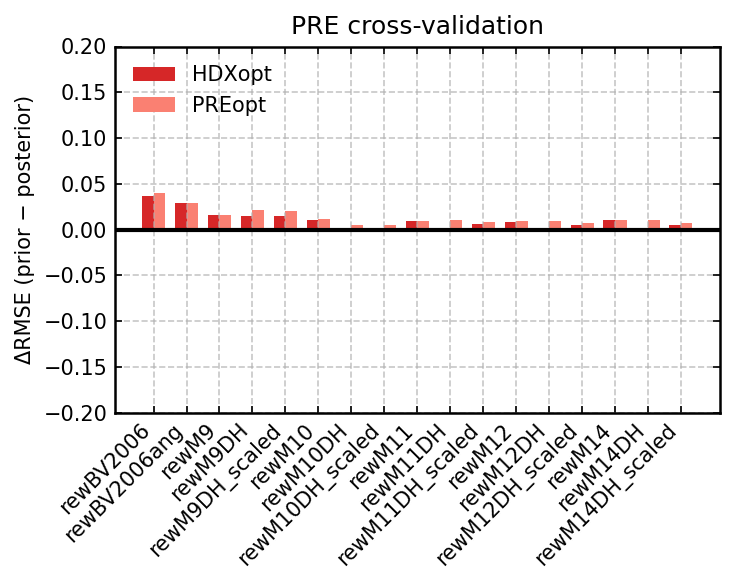

In [3]:
# summary barplot (delta Q-factor prior vs posterior)
# posterior 1 (HDXopt): best HDX fit (final point of the reweighting curve)
# posterior 2 (PREopt): best validation data fit (minimum point of the reweighting curve - if no improvement this is simply the prior)

proteins = ['ACTR', 'aSyn', 'd131d', 'drkN']

models = ['rewBV2006', 'rewBV2006ang', 'rewM9', 'rewM9DH', 'rewM9DH_scaled',
          'rewM10', 'rewM10DH','rewM10DH_scaled','rewM11', 'rewM11DH', 'rewM11DH_scaled',
          'rewM12', 'rewM12DH','rewM12DH_scaled','rewM14', 'rewM14DH', 'rewM14DH_scaled']

mean_diff1 = []
mean_diff2 = []

for model in models:

    prior = []
    post1 = []
    post2 = []

    for protein in proteins:
        dat = pd.read_csv(outpath+f'{protein}_{model}_PRE_validation.csv')

        prior.append(list(dat['PRE_RMSE'])[0])
        post1.append(list(dat['PRE_RMSE'])[-1])
        post2.append(np.min(dat['PRE_RMSE']))

    diff1 = np.array(prior)- np.array(post1)
    diff2 = np.array(prior)- np.array(post2)

    mean_diff1.append(np.mean(diff1))
    mean_diff2.append(np.mean(diff2))

df = pd.DataFrame()
df['Model']=models
df['HDXopt'] = mean_diff1
df['PREopt'] = mean_diff2





x = np.arange(len(df['Model']))          # positions for models
width = 0.35                             # width of the bars

fig, ax = plt.subplots(figsize=(5,4))

ax.bar(x - width/2, df['HDXopt'], width, label='HDXopt', color = 'tab:red')
ax.bar(x + width/2, df['PREopt'], width, label='PREopt ', color = 'salmon')

ax.set_ylabel('ΔRMSE (prior − posterior)')
ax.set_title('PRE cross-validation')
ax.set_xticks(x)
ax.axhline(0, color='black')
ax.set_ylim(-0.2,0.2)
ax.set_xticklabels(df['Model'], rotation=45, ha='right')
ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(outpath+f'PRE_validation_summary.png',dpi=300)





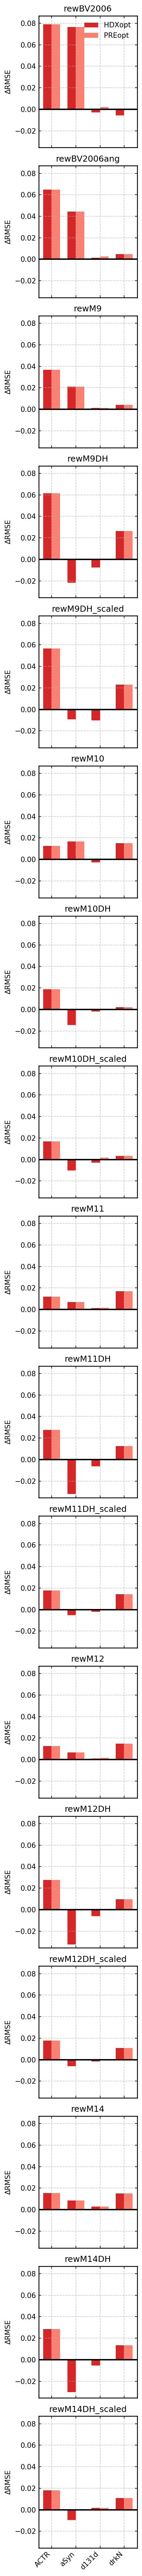

In [4]:


# ---- Compute ΔRMSE FOR EACH PROTEIN × MODEL ----
rows = []

for model in models:
    for protein in proteins:

        dat = pd.read_csv(outpath + f'{protein}_{model}_PRE_validation.csv')

        prior = list(dat['PRE_RMSE'])[0]
        post1 = list(dat['PRE_RMSE'])[-1]
        post2 = np.min(dat['PRE_RMSE'])

        delta_HDXopt = prior - post1
        delta_PREopt = prior - post2

        rows.append({
            "Model": model,
            "Protein": protein,
            "HDXopt": delta_HDXopt,
            "PREopt": delta_PREopt
        })

df = pd.DataFrame(rows)


# ---- PLOTTING ----
n_models = len(models)
x = np.arange(len(proteins))
width = 0.35

fig, axes = plt.subplots(
    n_models, 1,
    figsize=(3, 3 * n_models),
    sharex=True, sharey=True
)

if n_models == 1:
    axes = [axes]  # make iterable if only one model

# global y-limits
ymin = df[["HDXopt", "PREopt"]].min().min() * 1.1
ymax = df[["HDXopt", "PREopt"]].max().max() * 1.1

for idx, model in enumerate(models):
    ax = axes[idx]
    sub = df[df["Model"] == model]

    ax.bar(x - width/2, sub["HDXopt"], width, label="HDXopt", color="tab:red")
    ax.bar(x + width/2, sub["PREopt"], width, label="PREopt", color="salmon")

    ax.axhline(0, color="black")
    if ymin>0:
        ax.set_ylim(0, ymax)
    else:
        ax.set_ylim(ymin, ymax)
    ax.set_title(model)
    ax.set_ylabel("ΔRMSE")

    if idx == 0:
        ax.legend(loc="upper right")

axes[-1].set_xticks(x)
axes[-1].set_xticklabels(proteins, rotation=45, ha='right')

plt.tight_layout()
plt.savefig(outpath + "PRE_validation_per_protein_per_model.png", dpi=300)

